# Random Walk Simulation Using AgentPy

This notebook completes the laboratory tasks by tracking every path, supporting collision avoidance and directional preference, analyzing final positions, and comparing two reproducible scenarios.

In [4]:
import random
from collections import Counter
import agentpy as ap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
plt.style.use('seaborn-v0_8-whitegrid')

## Model

Each agent stores its initial position and every later position in `path`. A proposed move is clamped to the grid boundaries. With avoidance enabled, an agent chooses only currently unoccupied neighboring cells when possible. Directional preference is implemented as a probability of moving in the selected direction.

In [5]:
DIRECTIONS = [(1, 0), (-1, 0), (0, 1), (0, -1)]

class RandomWalker(ap.Agent):
    def setup(self):
        self.position = None
        self.path = []

    def choose_direction(self):
        preferred = tuple(self.model.p.preferred_direction)
        if preferred != (0, 0) and self.model.rng.random() < self.model.p.preference_strength:
            return preferred
        return self.model.rng.choice(DIRECTIONS)

    def candidate(self, direction):
        width, height = self.model.p.grid_size
        x = min(width - 1, max(0, self.position[0] + direction[0]))
        y = min(height - 1, max(0, self.position[1] + direction[1]))
        return (x, y)

    def step(self, occupied):
        directions = DIRECTIONS.copy()
        first = self.choose_direction()
        directions.remove(first)
        self.model.rng.shuffle(directions)
        directions.insert(0, first)
        if self.model.p.avoid_agents:
            open_positions = [self.candidate(d) for d in directions if self.candidate(d) not in occupied]
            new_position = open_positions[0] if open_positions else self.position
        else:
            new_position = self.candidate(first)
        occupied.discard(self.position)
        self.position = new_position
        occupied.add(self.position)
        self.path.append(self.position)

class RandomWalkModel(ap.Model):
    def setup(self):
        self.rng = random.Random(self.p.seed)
        self.agents = ap.AgentList(self, self.p.agents, RandomWalker)
        width, height = self.p.grid_size
        cells = [(x, y) for x in range(width) for y in range(height)]
        if self.p.avoid_agents and self.p.agents > len(cells):
            raise ValueError('Avoidance requires agents <= number of grid cells.')
        starts = self.rng.sample(cells, self.p.agents) if self.p.avoid_agents else [self.rng.choice(cells) for _ in self.agents]
        for agent, position in zip(self.agents, starts):
            agent.position = position
            agent.path = [position]

    def step(self):
        occupied = {agent.position for agent in self.agents}
        order = list(self.agents)
        self.rng.shuffle(order)
        for agent in order:
            agent.step(occupied)

    def run_steps(self):
        for _ in range(self.p.steps):
            self.step()
        return self

## Analysis and visualization helpers

In [6]:
def analyze_model(model, name):
    starts = np.array([a.path[0] for a in model.agents], dtype=float)
    finals = np.array([a.position for a in model.agents], dtype=float)
    distances = np.linalg.norm(finals - starts, axis=1)
    counts = Counter(map(tuple, finals.astype(int)))
    center = finals.mean(axis=0)
    spread = np.sqrt(np.mean(np.sum((finals - center) ** 2, axis=1)))
    return {'scenario': name, 'agents': len(model.agents), 'grid': f'{model.p.grid_size[0]} x {model.p.grid_size[1]}', 'steps': model.p.steps, 'occupied_cells': len(counts), 'overlapping_agents': len(model.agents) - len(counts), 'mean_displacement': distances.mean(), 'rms_spread_from_center': spread, 'center_x': center[0], 'center_y': center[1]}

def final_positions_table(model):
    return pd.DataFrame({'agent': range(1, len(model.agents) + 1), 'start': [a.path[0] for a in model.agents], 'final': [a.position for a in model.agents], 'path_length': [len(a.path) - 1 for a in model.agents], 'unique_cells_visited': [len(set(a.path)) for a in model.agents]})

def plot_paths(model, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    cmap = plt.get_cmap('tab20', len(model.agents))
    for i, agent in enumerate(model.agents):
        path = np.array(agent.path)
        ax.plot(path[:, 0], path[:, 1], alpha=0.7, linewidth=1.5, color=cmap(i))
        ax.scatter(*path[0], marker='o', s=25, color=cmap(i))
        ax.scatter(*path[-1], marker='X', s=70, color=cmap(i))
    width, height = model.p.grid_size
    ax.set(xlim=(-0.5, width - 0.5), ylim=(-0.5, height - 0.5), title=title, xlabel='x', ylabel='y')
    ax.set_xticks(range(width)); ax.set_yticks(range(height)); ax.set_aspect('equal')
    return ax

## Scenario 1: ordinary random movement

Ten agents move for 30 steps on a 10 × 10 grid. Multiple agents may occupy the same cell.

In [14]:
scenario_1 = {'agents': 10, 'grid_size': (10, 10), 'steps': 30, 'seed': 42, 'avoid_agents': False, 'preferred_direction': (0, 0), 'preference_strength': 0.0}
model_1 = RandomWalkModel(scenario_1)
model_1.setup(); model_1.run_steps()
display(final_positions_table(model_1))

,agent,start,final,path_length,unique_cells_visited
0,1,"(8, 1)","(7, 3)",30,12
1,2,"(1, 4)","(2, 2)",30,14
2,3,"(0, 3)","(0, 5)",30,9
3,4,"(9, 4)","(9, 7)",30,12
4,5,"(3, 5)","(8, 7)",30,22
5,6,"(3, 1)","(9, 9)",30,24
6,7,"(2, 8)","(2, 4)",30,17
7,8,"(1, 7)","(8, 4)",30,20
8,9,"(9, 4)","(6, 1)",30,12
9,10,"(1, 3)","(3, 8)",30,16


## Scenario 2: avoidance with an eastward preference

Twenty agents move for 60 steps on the same grid. They avoid occupied cells and attempt to move east 65% of the time. At the east boundary, clamping and avoidance redirect or stop them.

In [15]:
scenario_2 = {'agents': 20, 'grid_size': (10, 10), 'steps': 60, 'seed': 42, 'avoid_agents': True, 'preferred_direction': (1, 0), 'preference_strength': 0.65}
model_2 = RandomWalkModel(scenario_2)
model_2.setup(); model_2.run_steps()
display(final_positions_table(model_2))

,agent,start,final,path_length,unique_cells_visited
0,1,"(8, 1)","(8, 7)",60,19
1,2,"(1, 4)","(6, 2)",60,21
2,3,"(0, 3)","(9, 2)",60,25
3,4,"(9, 4)","(8, 4)",60,15
4,5,"(3, 5)","(8, 0)",60,25
5,6,"(3, 1)","(8, 5)",60,19
6,7,"(2, 8)","(9, 5)",60,21
7,8,"(1, 7)","(8, 8)",60,17
8,9,"(1, 3)","(8, 3)",60,19
9,10,"(8, 6)","(6, 1)",60,24


## Scenario comparison and final-position distribution

,agents,grid,steps,occupied_cells,overlapping_agents,mean_displacement,rms_spread_from_center,center_x,center_y
scenario,,,,,,,,,
1: random,10,10 x 10,30,10,0,4.61,4.05,5.4,5.00
2: avoidance + east preference,20,10 x 10,60,20,0,4.97,2.84,7.8,4.15


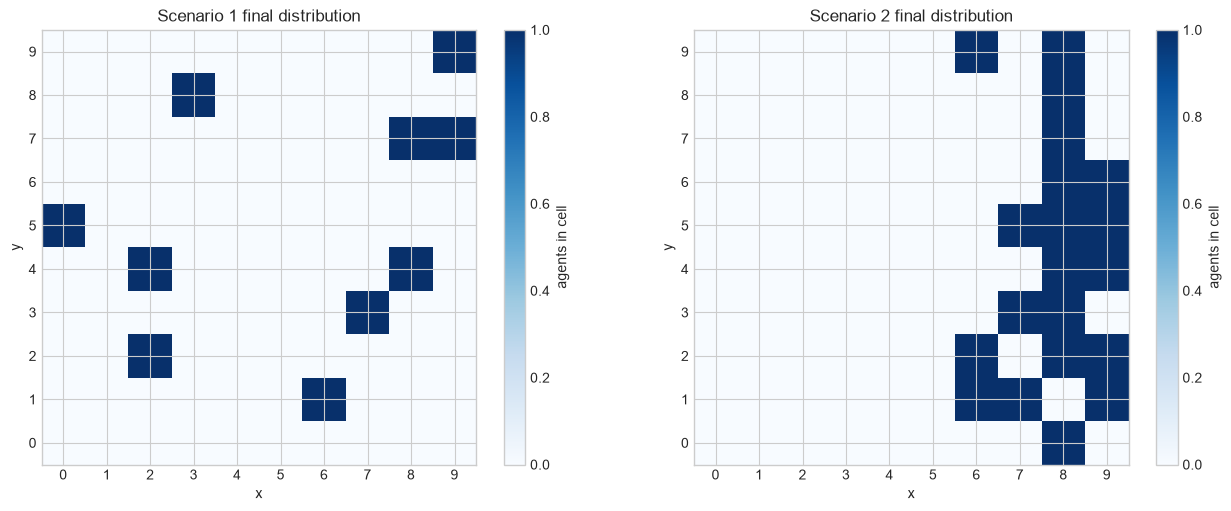

Interpretation: Scenario 1 remains an unbiased random walk and may contain overlaps.
Scenario 2 occupies distinct cells and shifts its center toward the eastern side because of the directional preference.


In [9]:
comparison = pd.DataFrame([analyze_model(model_1, '1: random'), analyze_model(model_2, '2: avoidance + east preference')]).set_index('scenario')
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, model, title in zip(axes, [model_1, model_2], ['Scenario 1 final distribution', 'Scenario 2 final distribution']):
    finals = np.array([a.position for a in model.agents])
    heat = np.zeros(model.p.grid_size, dtype=int)
    for x, y in finals: heat[x, y] += 1
    image = ax.imshow(heat.T, origin='lower', cmap='Blues', vmin=0)
    ax.set(title=title, xlabel='x', ylabel='y')
    ax.set_xticks(range(model.p.grid_size[0])); ax.set_yticks(range(model.p.grid_size[1]))
    fig.colorbar(image, ax=ax, label='agents in cell')
plt.show()
print('Interpretation: Scenario 1 remains an unbiased random walk and may contain overlaps.')
print('Scenario 2 occupies distinct cells and shifts its center toward the eastern side because of the directional preference.')